## Clustering: KMeans++, DBSCAN y jerárquico

Tres familias de clustering sobre las componentes principales de `a_preparacion`

### Constantes

- `K_RANGO`: valores de k evaluados; `K_ELEGIDO`: k final (justificado en §1.b)
- `MUESTRA_SIL`: la silueta es O(n²), se calcula sobre una muestra fija
- `MIN_SAMPLES`: 2 × dimensiones (regla de Ester et al., 1996, para DBSCAN)
- `N_JERARQ`: tamaño de la muestra estratificada del jerárquico (Ward es O(n²) en memoria)

In [1]:
K_RANGO     = range(2, 9)
K_ELEGIDO   = 6
MUESTRA_SIL = 10_000
N_JERARQ    = 3_000

### Utilidades

In [2]:
NOTEBOOK = "b_modelos"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)  # solo para guardar_tablas; el modelado es local (sklearn)

In [4]:
prep = pd.read_parquet(clust_dir / "preparado.parquet")
PCS = [c for c in prep.columns if c.startswith("pc_")]
P = prep[PCS].to_numpy()
MIN_SAMPLES = 2 * len(PCS)
rng = np.random.default_rng(SEMILLA)
idx_sil = rng.choice(len(P), MUESTRA_SIL, replace=False)
print(f"{len(P):,} proveedores × {len(PCS)} componentes | min_samples = {MIN_SAMPLES}")

86,011 proveedores × 5 componentes | min_samples = 10


---
### **1. KMeans++**

#### a. Selección de k

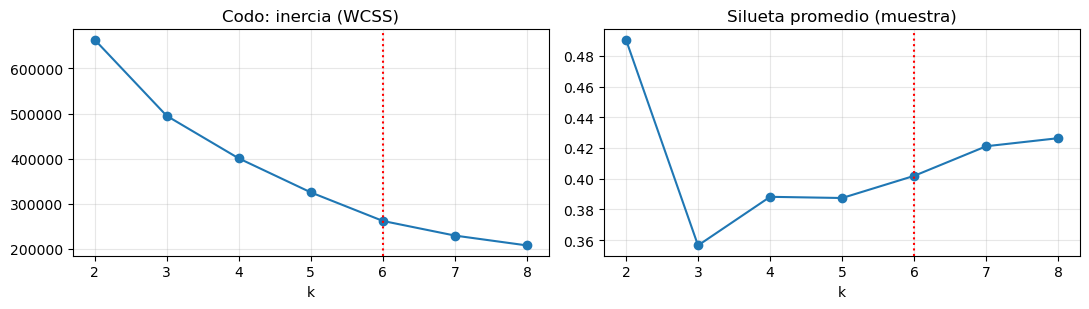

,k,inercia,silueta,cluster_min,caida_inercia
0,2,664075.121,0.491,13087,NaN
1,3,495013.163,0.357,10359,169061.957
2,4,400609.722,0.388,9043,94403.441
3,5,325108.225,0.387,8610,75501.497
4,6,261721.536,0.402,3198,63386.690
5,7,229244.908,0.421,3189,32476.628
6,8,207391.194,0.426,3091,21853.714


In [5]:
modelos, filas = {}, []
for k in K_RANGO:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEMILLA).fit(P)
    modelos[k] = km
    filas.append((k, km.inertia_, silhouette_score(P[idx_sil], km.labels_[idx_sil]), np.bincount(km.labels_).min()))
sel_k = pd.DataFrame(filas, columns=["k", "inercia", "silueta", "cluster_min"])
sel_k["caida_inercia"] = -sel_k.inercia.diff()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(sel_k.k, sel_k.inercia, "o-"); ax[0].set_title("Codo: inercia (WCSS)"); ax[0].set_xlabel("k")
ax[1].plot(sel_k.k, sel_k.silueta, "o-"); ax[1].set_title("Silueta promedio (muestra)"); ax[1].set_xlabel("k")
for a in ax:
    a.axvline(K_ELEGIDO, ls=":", color="red")
mostrar_fig("kmeans_seleccion_k")
sel_k.round(3)

- **k = 2 tiene la mejor silueta (0.49)** pero solo parte el mercado en dos: ~85% de proveedores ocasionales frente a
  ~15% recurrentes. Es la **polarización** de PQ-C1, y se retoma como el nivel superior del dendrograma (§3)
- **k = 6, el codo:** la caída de inercia pasa de 63k (5 → 6) a 32k (6 → 7); desde ahí cada clúster extra aporta la mitad
- **Silueta en k = 6 (0.40):** máximo local tras el valle de k = 3–5; k = 7–8 suben poco (0.42) y crean clústeres
  de ~3% difíciles de nombrar
- **Elegido k = 6:** mejor balance entre cohesión e interpretabilidad (arquetipos nombrables en `c_interpretacion`)

#### b. Modelo final y estabilidad

In [6]:
km = modelos[K_ELEGIDO]
prep["cluster_kmeans"] = km.labels_
prep["dist_centroide"] = np.linalg.norm(P - km.cluster_centers_[km.labels_], axis=1)

# estabilidad: misma k con otras semillas, comparadas con el modelo final
ari = [adjusted_rand_score(km.labels_, KMeans(K_ELEGIDO, init="k-means++", n_init=10, random_state=s).fit_predict(P))
       for s in (1, 2, 3, 4)]
print(f"ARI contra 4 semillas: {np.round(ari, 3)} | tamaños: {np.bincount(km.labels_)}")

ARI contra 4 semillas: [0.999 0.999 1.    0.999] | tamaños: [26225 10349 18574 16861  3198 10804]


- **ARI ≈ 1 entre semillas** indica que la partición no depende de la inicialización (k-means++ con 10 reinicios)
- `dist_centroide`: distancia de cada proveedor a su centroide; sirve como segundo indicador de atipicidad en §6

---
### **2. DBSCAN**

#### a. Calibración de eps

- **min_samples = 10** (2 × 5 componentes): un grupo denso necesita al menos 10 proveedores parecidos
- **eps:** codo de la curva de distancias al 10.º vecino (muestra de 20k); por debajo del codo los puntos están en zonas
  densas, por encima empiezan los aislados

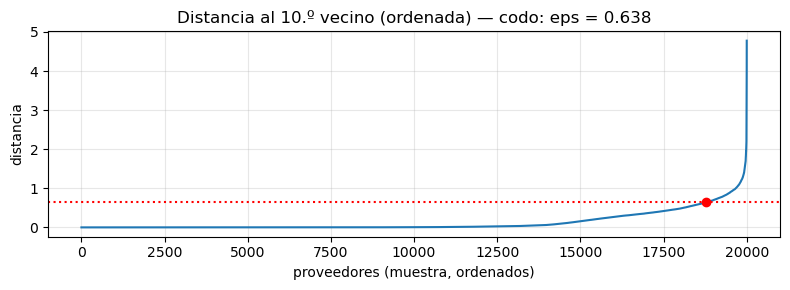

In [7]:
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(P)
dist_k = np.sort(nn.kneighbors(P[rng.choice(len(P), 20_000, replace=False)])[0][:, -1])
i_codo = codo(dist_k)
EPS = float(dist_k[i_codo])

plt.figure(figsize=(8, 3)); plt.plot(dist_k); plt.axhline(EPS, ls=":", color="red")
plt.scatter([i_codo], [EPS], color="red", zorder=3)
plt.title(f"Distancia al {MIN_SAMPLES}.º vecino (ordenada) — codo: eps = {EPS:.3f}")
plt.xlabel("proveedores (muestra, ordenados)"); plt.ylabel("distancia"); mostrar_fig("dbscan_kdist")

#### b. Ajuste

- **Duplicados:** miles de proveedores tienen vectores idénticos (p. ej. consorcio con 1 obra, 1 entidad). Se ajusta
  sobre los vectores **únicos** con `sample_weight` = repeticiones: el resultado es **idéntico** al de todos los puntos, con
  menos memoria (los vecindarios densos no se materializan miles de veces)

In [8]:
unicos, inversa, conteo = np.unique(P.round(6), axis=0, return_inverse=True, return_counts=True)
inversa = inversa.ravel()

def dbscan(eps):
    return DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(unicos, sample_weight=conteo).labels_[inversa]

t0 = time.time()
prep["cluster_density"] = dbscan(EPS)
ruido = prep.cluster_density == -1
print(f"vectores únicos: {len(unicos):,} de {len(P):,} | {time.time() - t0:.1f} s")
print(f"clústeres densos: {prep.cluster_density.max() + 1} | ruido: {ruido.sum():,} ({ruido.mean():.2%})")
prep.cluster_density.value_counts().head(8).to_frame("proveedores").T

vectores únicos: 73,816 de 86,011 | 3.1 s
clústeres densos: 45 | ruido: 3,577 (4.16%)


cluster_density,13,0,3,-1,25,20,4,30
proveedores,35382,21955,14902,3577,2788,2420,1037,505


#### c. Sensibilidad a eps

In [9]:
EPS_GRID = [0.4, 0.5, EPS, 0.8, 1.0]
sens = []
for e in EPS_GRID:
    lab = prep.cluster_density if e == EPS else dbscan(e)
    prep[f"ruido_eps_{e:.2f}"] = (lab == -1).astype(int)
    sens.append((round(e, 3), lab.max() + 1, (lab == -1).mean(), pd.Series(lab[lab >= 0]).value_counts(normalize=True).max()))
sens = pd.DataFrame(sens, columns=["eps", "clusters", "pct_ruido", "pct_cluster_mayor"])
sens.round(4)

,eps,clusters,pct_ruido,pct_cluster_mayor
0,0.400,69,0.1045,0.2853
1,0.500,54,0.0726,0.3440
2,0.638,45,0.0416,0.4292
3,0.800,36,0.0205,0.4664
4,1.000,11,0.0079,0.9817


- **eps = 0.638 (codo):** 45 grupos densos y **4.16% de ruido** (3,577 proveedores)
- **Por debajo** (0.4–0.5) el ruido sube a 7–10% y los arquetipos se fragmentan en decenas de micro-grupos; **por
  encima** (1.0) todo colapsa en un grupo con el 98% de los proveedores: el codo es el punto estable entre ambos
- **Formas no esféricas:** los grupos densos grandes coinciden con zonas de vectores casi idénticos (un solo proceso,
  una sola entidad); el ruido son los perfiles que **no tienen al menos 10 pares parecidos**
- La grilla queda exportada (`ruido_eps_*`) para el slider de eps en el reporte web

---
### **3. Jerárquico aglomerativo (Ward)**

- **Muestra estratificada** por clúster KMeans (proporcional, `N_JERARQ` = 3,000, semilla fija): conserva la mezcla de
  arquetipos y es reproducible
- **Ward + euclidiana:** une en cada paso los dos grupos que menos aumentan la varianza interna; es coherente con KMeans
  (minimizan el mismo criterio) y permite comparar ambas particiones

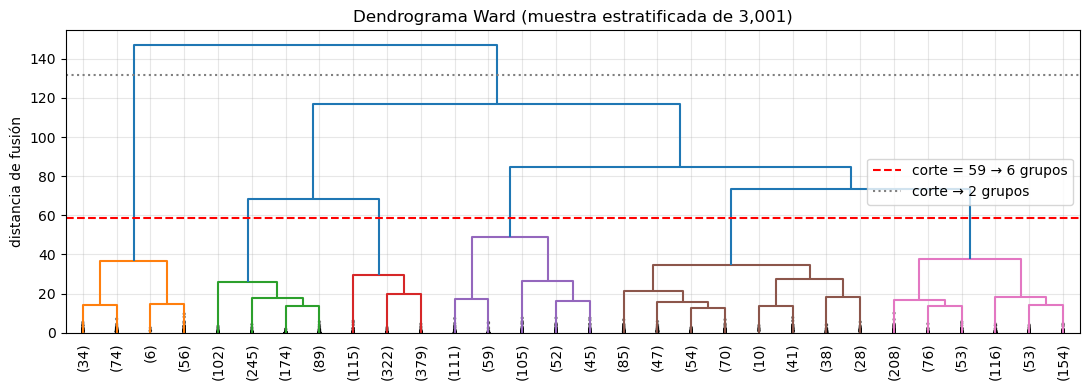

ARI jerárquico vs. KMeans (k = 6, muestra): 0.752


cluster_jerarquico,0,1,2,3,4,5
cluster_kmeans,,,,,,
0,0,33,787,2,0,93
1,58,0,0,0,288,15
2,0,577,29,19,23,0
3,0,0,0,11,37,540
4,112,0,0,0,0,0
5,0,0,0,340,25,12


In [10]:
muestra = (prep.groupby("cluster_kmeans", group_keys=False)
               .apply(lambda g: g.sample(max(1, round(N_JERARQ * len(g) / len(prep))), random_state=SEMILLA)))
Z = linkage(muestra[PCS].to_numpy(), method="ward")
corte = (Z[-K_ELEGIDO, 2] + Z[-K_ELEGIDO + 1, 2]) / 2   # altura entre la fusión que deja k y la que deja k − 1 grupos
muestra["cluster_jerarquico"] = fcluster(Z, t=corte, criterion="distance") - 1

plt.figure(figsize=(11, 4))
dendrogram(Z, truncate_mode="lastp", p=30, show_contracted=True, leaf_rotation=90, color_threshold=corte)
plt.axhline(corte, ls="--", color="red", label=f"corte = {corte:.0f} → {K_ELEGIDO} grupos")
plt.axhline((Z[-2, 2] + Z[-1, 2]) / 2, ls=":", color="gray", label="corte → 2 grupos")
plt.title(f"Dendrograma Ward (muestra estratificada de {len(muestra):,})"); plt.ylabel("distancia de fusión")
plt.legend(); mostrar_fig("dendrograma")

ari_jk = adjusted_rand_score(muestra.cluster_kmeans, muestra.cluster_jerarquico)
print(f"ARI jerárquico vs. KMeans (k = {K_ELEGIDO}, muestra): {ari_jk:.3f}")
pd.crosstab(muestra.cluster_kmeans, muestra.cluster_jerarquico)

- **Corte a 6 grupos** en la altura media entre la 5.ª y la 6.ª fusión desde arriba (≈ 59): es el salto más largo bajo
  el que no se mezclan arquetipos; coincide con k = 6 de KMeans (ARI = 0.75)
- **Nivel superior (2 grupos):** el primer corte aísla una rama chica (~6% de la muestra) de **proveedores recurrentes
  de gran alcance** frente a todo el resto: la polarización de PQ-C1 aparece también aquí
- **Nivel intermedio:** el resto se separa en **consorcios** (de obra y de servicios, un solo proceso) frente a
  **empresas y personas individuales**; estas últimas se dividen en recurrentes medianas, bienes ocasionales y
  adjudicaciones sin competencia
- **Diferencias con KMeans:** el jerárquico parte el clúster de recurrentes medianos en dos (los más activos se unen a los
  grandes): KMeans corta por distancia al centroide, Ward por varianza de la fusión

---
### **4. Escritura**

- `data/clustering/etiquetas.parquet`: etiquetas KMeans (k elegido y k = 2…8 para el slider de la web), DBSCAN (eps
  elegido y la grilla), distancia al centroide y PC1–PC2

In [11]:
for k, m in modelos.items():
    prep[f"kmeans_k{k}"] = m.labels_
prep.to_parquet(clust_dir / "etiquetas.parquet", index=False)
muestra[["proveedor_key", "cluster_jerarquico"]].to_parquet(clust_dir / "jerarquico_muestra.parquet", index=False)

escritos = guardar_tablas({"kmeans_seleccion_k": sel_k, "dbscan_sensibilidad": sens,
                           "jerarquico_vs_kmeans": pd.crosstab(muestra.cluster_kmeans, muestra.cluster_jerarquico)
                                                       .reset_index().rename(columns=str)})
print(f"etiquetas: {len(prep):,} proveedores | eps = {EPS:.3f} | k = {K_ELEGIDO}")

Escrito en 02_Clustering/temp/b_modelos/: kmeans_seleccion_k, dbscan_sensibilidad, jerarquico_vs_kmeans
etiquetas: 86,011 proveedores | eps = 0.638 | k = 6


In [12]:
verificar_salidas(escritos)

OK: 3 tablas (parquet + json) | 3 figuras: dbscan_kdist, dendrograma, kmeans_seleccion_k


---
### Cerrar sesión

In [13]:
spark.stop()